# Gasification surrogate models: regression and ANN

Surrogate models that predict four gasification outputs from four operating conditions of a process simulation.

| Inputs (operating conditions) | Outputs |
|---|---|
| Pressure (kPa), equivalence ratio ER, moisture content MC (wt fraction), temperature (°C) | H₂ (%), syngas LHV (MJ/kmol), efficiency η (%), λ (g/mol) |

Models compared: a mean baseline, linear regression, two quadratic regressions and several multilayer perceptrons (MLPs), including a 36-configuration validation search.

**Workflow.** Rows that share identical inputs are kept together when splitting (train / validation / test ≈ 56 / 14 / 30 %). All scalers are fitted on training rows only. Every model is chosen on the validation rows *before* the test rows are touched, then refitted on training + validation rows and scored once on the test rows.

**Data.** The simulation table is confidential and is not included in this repository.

## 1. Setup

In [2]:
from pathlib import Path
import importlib.metadata
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

#import mlp_hyperparameter_search   # names used directly

SEED = 1

## 2. Input data

In [3]:
data = pd.read_csv("/content/gasification_simulation.csv")
data.columns = data.columns.astype(str).str.strip()
data = data.rename(columns={
    "Pressure (kPa)": "Pressure",
    "MC (wt%)": "MC",
    "Temperature (°C)": "Temperature",
    "H2 (%)": "H2",
    "LHV (MJ/kmol)": "LHV",
    "η (%)": "η",
    "λ (g/mol)": "λ",
})

predictors = ["Pressure", "ER", "MC", "Temperature"]
targets = ["H2", "LHV", "η", "λ"]

if not data.columns.is_unique:
    raise ValueError("Duplicate column names after renaming the dataset headers.")
missing_columns = set(predictors + targets) - set(data.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {', '.join(sorted(missing_columns))}")

data = data[predictors + targets].apply(pd.to_numeric, errors="raise")
if not np.isfinite(data.to_numpy()).all():
    raise ValueError("The dataset contains missing or non-finite values.")
if (data[targets] <= 0).any().any():
    raise ValueError("MAPE below assumes strictly positive responses.")

data_x = data[predictors]
data_y = data[targets]
print(f"Dataset: {data.shape[0]} rows, {len(predictors)} inputs, {len(targets)} outputs")
data.describe().round(4)

Dataset: 10000 rows, 4 inputs, 4 outputs


,Pressure,ER,MC,Temperature,H2,LHV,η,λ
count,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000
mean,550.0000,0.3500,0.2000,850.0001,15.4540,131.2949,93.9421,4.7490
std,259.8463,0.0289,0.0577,86.6148,3.1728,14.6026,2.3727,3.0956
min,100.0000,0.3000,0.1000,700.0000,5.9050,109.7000,88.6800,0.1061
25%,324.9750,0.3250,0.1500,775.0000,14.0975,118.7000,92.0400,1.8817
50%,550.0000,0.3500,0.2000,850.0000,17.2900,129.1000,95.0100,4.5965
75%,775.0250,0.3750,0.2500,925.0000,17.6600,142.7000,96.0100,7.5312
max,1000.0000,0.4000,0.3000,1000.0000,17.7600,162.1000,96.3200,10.1200


## 3. Structure of the experimental design

The simulation varies all four operating conditions **together** along one operating path: when pressure rises, ER, MC and temperature rise in step. This is a property of the experiment design, and all four conditions are kept as model inputs because they are the conditions that define each run.

The cells below quantify this, because it decides how the results should be read:

- **The models learn a response along one path.** They map a point on the operating path to the four outputs. They are not validated for combinations away from that path (for example high pressure with low temperature), and their predictions there should not be trusted.
- **Individual input effects cannot be separated.** With perfectly co-varying inputs, the data cannot tell the effect of pressure apart from the effect of temperature. Regression coefficients are therefore not interpreted, and the quadratic design matrix is badly conditioned (shown in section 6).
- **The random test split measures interpolation.** Test rows sit between closely spaced training rows on the same path. Section 12 adds a harder check that holds out the upper end of the path.

To show the path, each input is rescaled to 0–1 over its observed range; the mean of the four rescaled values is the *sweep position*.

In [4]:
print("Input correlation matrix:")
print(data_x.corr().round(6).to_string())

input_ranges = data_x.max() - data_x.min()
rescaled_inputs = (data_x - data_x.min()) / input_ranges
sweep_position = rescaled_inputs.mean(axis=1)
max_gap = (rescaled_inputs.max(axis=1) - rescaled_inputs.min(axis=1)).max()
print(f"\nLargest gap between the rescaled inputs within any row: {max_gap:.4f}")

singular_values = np.linalg.svd(
    rescaled_inputs - rescaled_inputs.mean(), compute_uv=False
)
variance_share = singular_values ** 2 / np.sum(singular_values ** 2)
print("Share of input variance per principal component:",
      np.array2string(variance_share, precision=8))

Input correlation matrix:
             Pressure        ER        MC  Temperature
Pressure          1.0  1.000000  1.000000          1.0
ER                1.0  1.000000  0.999999          1.0
MC                1.0  0.999999  1.000000          1.0
Temperature       1.0  1.000000  1.000000          1.0

Largest gap between the rescaled inputs within any row: 0.0010
Share of input variance per principal component: [9.99999744e-01 2.05118277e-07 3.99885851e-08 1.05560391e-08]


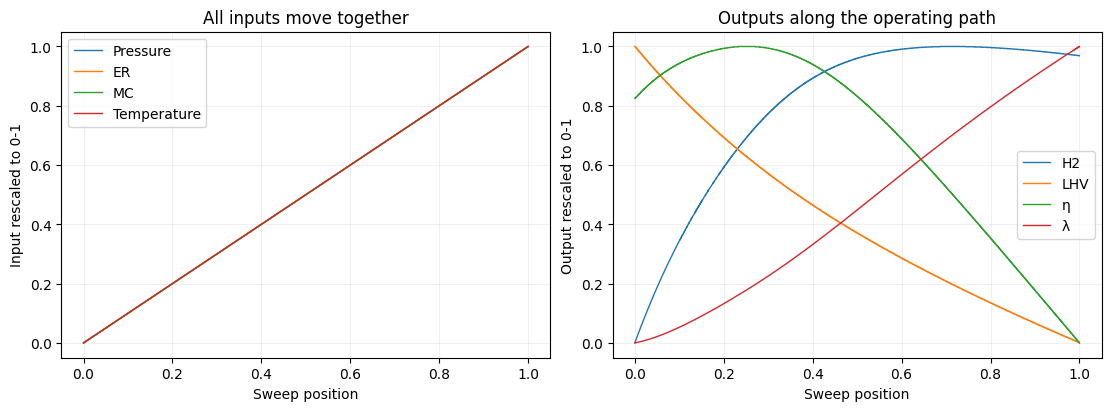

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for name in predictors:
    axes[0].plot(sweep_position, rescaled_inputs[name], label=name, lw=1)
axes[0].set(xlabel="Sweep position", ylabel="Input rescaled to 0-1",
            title="All inputs move together")
axes[0].legend()
for name in targets:
    response = data_y[name]
    axes[1].plot(sweep_position, (response - response.min()) / (response.max() - response.min()),
                 label=name, lw=1)
axes[1].set(xlabel="Sweep position", ylabel="Output rescaled to 0-1",
            title="Outputs along the operating path")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig("operating_path.png", dpi=160)
plt.show()

## 4. Train, validation and test split

Rows with identical inputs form one group and are never split across subsets. Groups are split 70 / 30 into development and test, and development groups 80 / 20 into training and validation (≈ 56 / 14 / 30 % of rows).

In [6]:
print("Exact duplicate rows:", data.duplicated().sum())
group_sizes = data.groupby(predictors, sort=False).size()
print("Input combinations that appear more than once:", (group_sizes > 1).sum())

input_groups = data.groupby(predictors, sort=False).ngroup()
unique_groups = input_groups.unique()

development_groups, test_groups = train_test_split(
    unique_groups, test_size=0.30, random_state=SEED
)
train_groups, validation_groups = train_test_split(
    development_groups, test_size=0.20, random_state=SEED
)

train_rows = data.index[input_groups.isin(train_groups)]
validation_rows = data.index[input_groups.isin(validation_groups)]
test_rows = data.index[input_groups.isin(test_groups)]
development_rows = data.index[input_groups.isin(development_groups)]

train_x, train_y = data_x.loc[train_rows], data_y.loc[train_rows]
validation_x, validation_y = data_x.loc[validation_rows], data_y.loc[validation_rows]
test_x, test_y = data_x.loc[test_rows], data_y.loc[test_rows]
development_x, development_y = data_x.loc[development_rows], data_y.loc[development_rows]

assert set(train_groups).isdisjoint(validation_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(validation_groups).isdisjoint(test_groups)
assert len(train_x) + len(validation_x) + len(test_x) == len(data)

print(pd.DataFrame({
    "Subset": ["Training", "Validation", "Test"],
    "Rows": [len(train_x), len(validation_x), len(test_x)],
}).to_string(index=False))

Exact duplicate rows: 23
Input combinations that appear more than once: 778
    Subset  Rows
  Training  5615
Validation  1389
      Test  2996


## 5. Scaling and evaluation helpers

Input and target scalers are fitted on training rows only. MLPs are trained on standardised targets and their predictions are transformed back to original units.

**Normalised RMSE** = RMSE / standard deviation of the target in the training rows. This fixed reference is used for validation, test and extrapolation scores so they are on the same scale. It also matches the score used in the MLP search, where RMSE on standardised targets equals this ratio.

In [7]:
scaler_x = StandardScaler()
train_x_scaled = scaler_x.fit_transform(train_x)
validation_x_scaled = scaler_x.transform(validation_x)

scaler_y = StandardScaler()
train_y_scaled = scaler_y.fit_transform(train_y)
validation_y_scaled = scaler_y.transform(validation_y)

reference_std = train_y.std(ddof=0)
if (reference_std <= 0).any():
    raise ValueError("Each response must vary in the training subset.")


def score_predictions(actual, predicted_by_model):
    # Per-model, per-target MAE, RMSE, R2, MAPE and normalised RMSE.
    records = []
    for model_name, predicted in predicted_by_model.items():
        assert predicted.index.equals(actual.index)
        assert predicted.columns.equals(actual.columns)
        assert np.isfinite(predicted.to_numpy()).all()
        for target in actual.columns:
            y_true = actual[target].to_numpy()
            y_pred = predicted[target].to_numpy()
            rmse = np.sqrt(mean_squared_error(y_true, y_pred))
            records.append({
                "Model": model_name,
                "Target": target,
                "MAE": mean_absolute_error(y_true, y_pred),
                "RMSE": rmse,
                "R2": r2_score(y_true, y_pred),
                "MAPE_pct": 100 * np.mean(np.abs((y_true - y_pred) / y_true)),
                "Normalised_RMSE": rmse / reference_std[target],
            })
    return pd.DataFrame(records)


def as_frame(values, index):
    return pd.DataFrame(values, index=index, columns=targets)


def fit_mlp(model, x_fit, y_fit_scaled, x_predict, y_scaler):
    # Fit an MLP on standardised targets; return predictions in original units
    # and whether a ConvergenceWarning was raised.
    with warnings.catch_warnings(record=True) as recorded, threadpool_limits(limits=1):
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x_fit, y_fit_scaled)
        predicted = y_scaler.inverse_transform(model.predict(x_predict))
    warned = any(issubclass(w.category, ConvergenceWarning) for w in recorded)
    return predicted, warned

## 6. Regression models

- **Linear regression**: one linear model per output (fitted jointly; the result is identical to four separate fits).
- **Reg1, full quadratic**: linear, squared and pairwise interaction terms.
- **Reg2, squared terms**: linear and squared terms, no interactions.

Because the inputs co-vary, the design matrices are badly conditioned. They are numerically full rank only because rounding in the table adds tiny independent variation (about 1e-7 of the input variance, section 3). The fits use those directions to model rounding noise, so the coefficients have no physical meaning and are not reported. Predictions along the path are still usable. The two quadratic models give practically identical predictions; on a tie the first listed wins the selection.

In [8]:
polynomial = PolynomialFeatures(degree=2, include_bias=False)
regression_features = {
    "Linear regression": lambda x: x,
    "Reg1 full quadratic": lambda x: polynomial.transform(x),
    "Reg2 squared terms": lambda x: np.column_stack([x, x ** 2]),
}
polynomial.fit(train_x_scaled)

for name, make_features in regression_features.items():
    design = make_features(train_x_scaled)
    print(f"{name:20s} terms: {design.shape[1]:2d}   "
          f"independent columns (rank): {np.linalg.matrix_rank(design):2d}   "
          f"condition number: {np.linalg.cond(design):.2e}")

regression_models = {name: LinearRegression() for name in regression_features}
validation_predictions = {
    "Mean": as_frame(np.tile(train_y.mean().to_numpy(), (len(validation_y), 1)),
                     validation_y.index),
}
for name, make_features in regression_features.items():
    regression_models[name].fit(make_features(train_x_scaled), train_y)
    validation_predictions[name] = as_frame(
        regression_models[name].predict(make_features(validation_x_scaled)),
        validation_y.index,
    )

Linear regression    terms:  4   independent columns (rank):  4   condition number: 9.64e+03
Reg1 full quadratic  terms: 14   independent columns (rank): 14   condition number: 1.01e+08
Reg2 squared terms   terms:  8   independent columns (rank):  8   condition number: 1.30e+04


## 7. MLP models

The hand-picked architectures from the original study are kept. All use ReLU and a fixed seed.

Adam runs use `tol=1e-6` and `n_iter_no_change=20` on the training loss (set in `mlp_hyperparameter_search.py`). With scikit-learn's default tolerance (1e-4), these runs stopped after a few dozen epochs, well before the loss settled. Scikit-learn's built-in `early_stopping` is not used: it carves a *random* internal validation set from the training rows, which ignores the input groups. The external validation rows already serve that purpose.

In [9]:
from mlp_hyperparameter_search import tune_mlp, ADAM_STOPPING

ann_configs = {
    "MLP baseline": MLPRegressor(
        hidden_layer_sizes=(2,), activation="relu", solver="adam", alpha=0.0001,
        learning_rate_init=0.001, max_iter=2000, random_state=SEED, **ADAM_STOPPING),
    "MLP 1": MLPRegressor(
        hidden_layer_sizes=(12,), activation="relu", solver="lbfgs", alpha=0.005,
        max_iter=2000, random_state=SEED),
    "MLP 2": MLPRegressor(
        hidden_layer_sizes=(15,), activation="relu", solver="lbfgs", alpha=0.0000005,
        max_iter=2000, random_state=SEED),
    "MLP 3": MLPRegressor(
        hidden_layer_sizes=(10, 10), activation="relu", solver="adam", alpha=0.0000005,
        learning_rate_init=0.001, max_iter=2000, random_state=SEED, **ADAM_STOPPING),
    "MLP 4": MLPRegressor(
        hidden_layer_sizes=(10, 15, 10), activation="relu", solver="adam", alpha=0.0005,
        learning_rate_init=0.001, max_iter=2000, random_state=SEED, **ADAM_STOPPING),
}

ann_models, ann_warnings = {}, {}
for name, config in ann_configs.items():
    model = clone(config)
    predicted, warned = fit_mlp(model, train_x_scaled, train_y_scaled,
                                validation_x_scaled, scaler_y)
    ann_models[name], ann_warnings[name] = model, warned
    validation_predictions[name] = as_frame(predicted, validation_y.index)
    print(f"{name:12s} iterations: {model.n_iter_:4d}   convergence warning: {warned}")

MLP baseline iterations:  287   convergence warning: False
MLP 1        iterations:  331   convergence warning: False
MLP 2        iterations:  239   convergence warning: False
MLP 3        iterations:  329   convergence warning: False
MLP 4        iterations:  136   convergence warning: False


### MLP hyperparameter search

36 configurations (4 architectures × 3 L2 penalties × 3 solver settings), ranked by mean normalised validation RMSE. The search code is in `mlp_hyperparameter_search.py`.

In [10]:
mlp_search_table, model_mlp_tuned, tuned_fit_warnings = tune_mlp(
    train_x_scaled, train_y_scaled, validation_x_scaled, validation_y_scaled, seed=SEED,
)
ann_models["MLP tuned"] = model_mlp_tuned
ann_warnings["MLP tuned"] = any(
    issubclass(w.category, ConvergenceWarning) for w in tuned_fit_warnings
)
validation_predictions["MLP tuned"] = as_frame(
    scaler_y.inverse_transform(model_mlp_tuned.predict(validation_x_scaled)),
    validation_y.index,
)
mlp_search_table

,Hidden_layers,Solver,Alpha,Initial_learning_rate,Iterations,Convergence_warning,Mean_normalised_RMSE
0,"(10, 15, 10)",lbfgs,5.000000e-04,NaN,703,False,0.004416
1,"(10, 10)",adam,5.000000e-03,0.005,529,False,0.005608
2,"(10, 15, 10)",lbfgs,5.000000e-03,NaN,504,False,0.005886
3,"(10, 15, 10)",lbfgs,5.000000e-07,NaN,492,False,0.005990
4,"(10, 10)",lbfgs,5.000000e-03,NaN,501,False,0.006098
5,"(10, 15, 10)",adam,5.000000e-03,0.001,455,False,0.006319
6,"(10, 10)",lbfgs,5.000000e-04,NaN,401,False,0.006651
7,"(10, 10)",lbfgs,5.000000e-07,NaN,403,False,0.007087
8,"(10, 15, 10)",adam,5.000000e-04,0.005,131,False,0.007159
9,"(10, 15, 10)",adam,5.000000e-04,0.001,136,False,0.007201


## 8. Model selection on validation rows

Criterion: lowest mean normalised validation RMSE across the four outputs. Selections are fixed here, before any test row is used. The best MLPs are close, so their order can change on the test rows; the selection is not revised after testing.

In [13]:
validation_metrics = score_predictions(validation_y, validation_predictions)
validation_summary = validation_metrics.groupby("Model", sort=False).agg(
    Mean_normalised_RMSE=("Normalised_RMSE", "mean")
)
validation_summary["Iterations"] = pd.Series(
    {name: model.n_iter_ for name, model in ann_models.items()}
)
validation_summary["Convergence_warning"] = pd.Series(ann_warnings)

regression_names = list(regression_features)
best_regression_name = validation_summary.loc[regression_names, "Mean_normalised_RMSE"].idxmin()
best_ann_name = validation_summary.loc[list(ann_models), "Mean_normalised_RMSE"].idxmin()
best_model_name = validation_summary["Mean_normalised_RMSE"].idxmin()

print(validation_summary.sort_values("Mean_normalised_RMSE").round(6).to_string())
print("\nSelected regression before testing:", best_regression_name)
print("Selected ANN before testing:", best_ann_name)
print("Selected overall model before testing:", best_model_name)

                     Mean_normalised_RMSE  Iterations Convergence_warning
Model                                                                    
MLP tuned                        0.004416       703.0               False
MLP 4                            0.007201       136.0               False
MLP 1                            0.008400       331.0               False
MLP 3                            0.010367       329.0               False
MLP 2                            0.011496       239.0               False
MLP baseline                     0.063673       287.0               False
Reg2 squared terms               0.076401         NaN                 NaN
Reg1 full quadratic              0.076462         NaN                 NaN
Linear regression                0.288592         NaN                 NaN
Mean                             1.019414         NaN                 NaN

Selected regression before testing: Reg2 squared terms
Selected ANN before testing: MLP tuned
Selected overall 

## 9. Refit on training + validation rows

Scalers and every model are refitted on the development rows with unchanged settings, then used once on the test rows.

In [15]:
scaler_x_final = StandardScaler()
development_x_scaled = scaler_x_final.fit_transform(development_x)
test_x_scaled = scaler_x_final.transform(test_x)

scaler_y_final = StandardScaler()
development_y_scaled = scaler_y_final.fit_transform(development_y)

polynomial.fit(development_x_scaled)

test_predictions = {
    "Mean": as_frame(np.tile(development_y.mean().to_numpy(), (len(test_y), 1)),
                     test_y.index),
}
for name, make_features in regression_features.items():
    final_model = clone(regression_models[name]).fit(
        make_features(development_x_scaled), development_y
    )
    test_predictions[name] = as_frame(
        final_model.predict(make_features(test_x_scaled)), test_y.index
    )

final_ann_models, final_ann_warnings = {}, {}
for name, model in ann_models.items():
    final_model = clone(model)
    predicted, warned = fit_mlp(final_model, development_x_scaled, development_y_scaled,
                                test_x_scaled, scaler_y_final)
    final_ann_models[name], final_ann_warnings[name] = final_model, warned
    test_predictions[name] = as_frame(predicted, test_y.index)

fit_diagnostics = pd.DataFrame({
    "Model": list(final_ann_models),
    "Iterations": [model.n_iter_ for model in final_ann_models.values()],
    "Convergence_warning": list(final_ann_warnings.values()),
})
print(fit_diagnostics.to_string(index=False))

       Model  Iterations  Convergence_warning
MLP baseline         263                False
       MLP 1         404                False
       MLP 2         235                False
       MLP 3         297                False
       MLP 4         122                False
   MLP tuned         473                False


## 10. Test metrics

MAPE for λ is large for every model because λ approaches 0.1 g/mol at the start of the path, so small absolute errors become large percentages there. RMSE and normalised RMSE are the better comparison for λ.

In [14]:
metric_df = score_predictions(test_y, test_predictions)
print(metric_df.round(6).to_string(index=False))

              Model Target       MAE      RMSE        R2   MAPE_pct  Normalised_RMSE
               Mean     H2  2.513133  3.106991 -0.000467  20.753060         0.970256
               Mean    LHV 12.316833 14.416308 -0.000058   9.407383         0.985605
               Mean      η  2.064273  2.363425 -0.000140   2.216283         1.001618
               Mean      λ  2.699557  3.070506 -0.000000 237.564157         0.993700
  Linear regression     H2  1.434374  1.683028  0.706434  10.896602         0.525579
  Linear regression    LHV  1.710775  2.006798  0.980621   1.298867         0.137200
  Linear regression      η  0.832387  0.970886  0.831223   0.885269         0.411461
  Linear regression      λ  0.152805  0.191116  0.996126  20.238848         0.061850
Reg1 full quadratic     H2  0.358376  0.415495  0.982108   2.598404         0.129751
Reg1 full quadratic    LHV  0.364280  0.425923  0.999127   0.277749         0.029119
Reg1 full quadratic      η  0.202017  0.232948  0.990284   0.2157

In [16]:
test_summary = metric_df.groupby("Model", sort=False).agg(
    Mean_normalised_RMSE=("Normalised_RMSE", "mean"),
    Mean_R2=("R2", "mean"),
)
print(test_summary.sort_values("Mean_normalised_RMSE").round(6).to_string())

                     Mean_normalised_RMSE   Mean_R2
Model                                              
MLP tuned                        0.005282  0.999971
MLP 4                            0.006694  0.999952
MLP 1                            0.008156  0.999922
MLP 3                            0.009778  0.999891
MLP 2                            0.011377  0.999840
MLP baseline                     0.062848  0.994681
Reg1 full quadratic              0.074847  0.992438
Reg2 squared terms               0.074852  0.992436
Linear regression                0.284022  0.878601
Mean                             0.987795 -0.000166


## 11. Figures

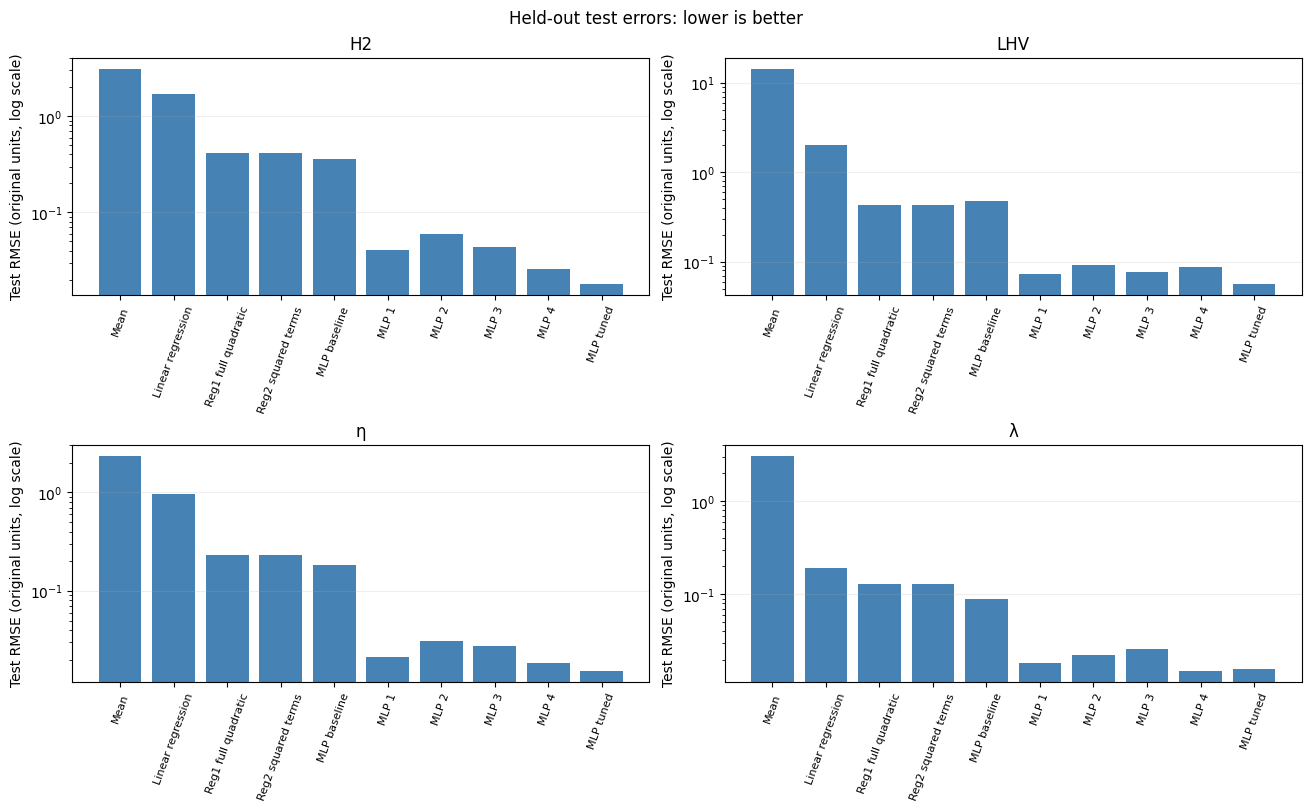

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
for ax, target in zip(axes.flat, targets):
    target_metrics = metric_df.loc[metric_df["Target"] == target]
    ax.bar(target_metrics["Model"], target_metrics["RMSE"], color="steelblue")
    ax.set_yscale("log")
    ax.set_title(target)
    ax.set_ylabel("Test RMSE (original units, log scale)")
    ax.tick_params(axis="x", labelrotation=70, labelsize=8)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Held-out test errors: lower is better")
fig.savefig("test_rmse.png", dpi=160)
plt.show()

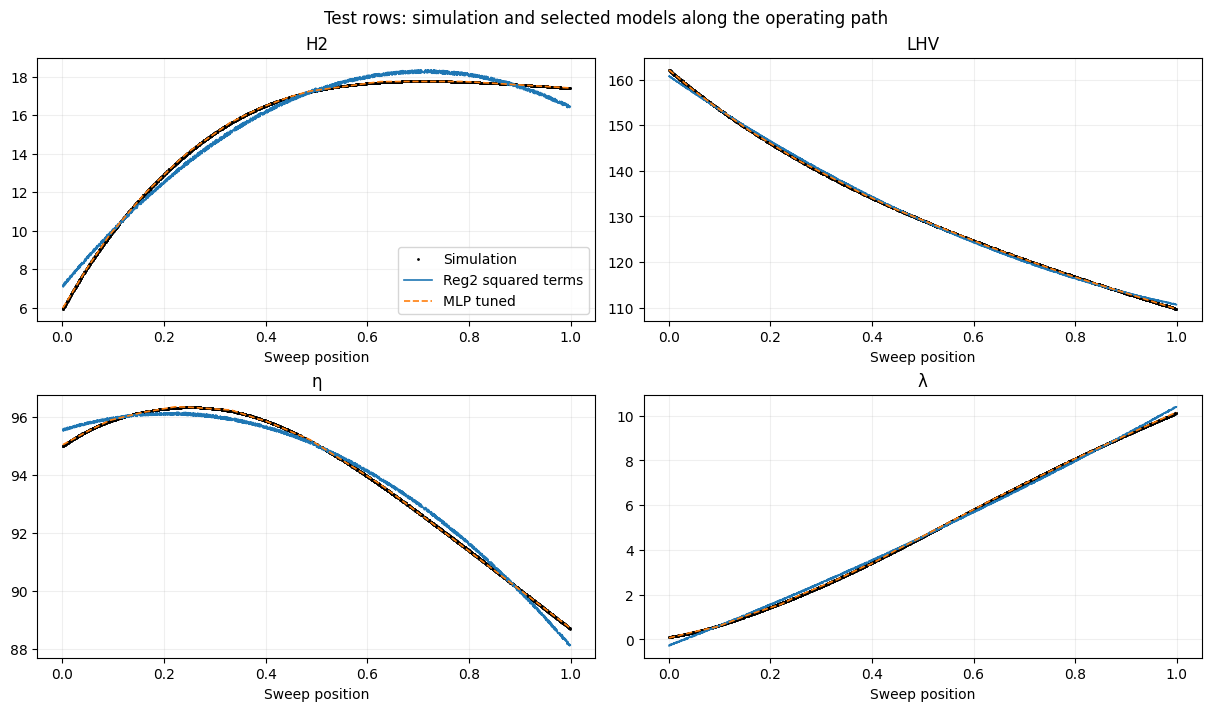

In [19]:
order = sweep_position.loc[test_y.index].sort_values().index
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, target in zip(axes.flat, targets):
    ax.plot(sweep_position[order], test_y.loc[order, target], "k.", ms=2, label="Simulation")
    ax.plot(sweep_position[order], test_predictions[best_regression_name].loc[order, target],
            lw=1.2, label=best_regression_name)
    ax.plot(sweep_position[order], test_predictions[best_ann_name].loc[order, target],
            lw=1.2, ls="--", label=best_ann_name)
    ax.set(title=target, xlabel="Sweep position")
    ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle("Test rows: simulation and selected models along the operating path")
fig.savefig("test_predictions_along_path.png", dpi=160)
plt.show()

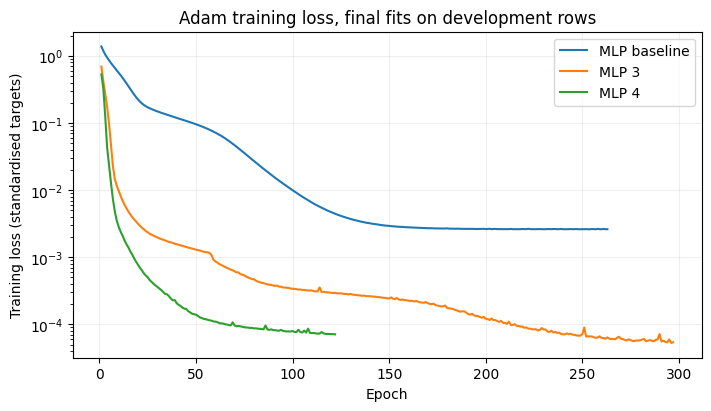

In [20]:
# lbfgs does not record a loss curve, so only the adam models are shown.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name, model in final_ann_models.items():
    if model.solver == "adam":
        ax.plot(np.arange(1, len(model.loss_curve_) + 1), model.loss_curve_, label=name)
ax.set(xlabel="Epoch", ylabel="Training loss (standardised targets)", yscale="log",
       title="Adam training loss, final fits on development rows")
ax.legend()
ax.grid(alpha=0.2)
fig.savefig("adam_loss_curves.png", dpi=160)
plt.show()

## 12. Extrapolation check along the operating path

The random test split asks the models to fill gaps between nearby training points. This check is harder: the selected regression and the selected ANN are refitted, with their settings unchanged, on the lower 85 % of the path (sweep position ≤ 0.85) and scored on the upper 15 %. It is a stress test only and played no part in model selection.

Compare models on normalised RMSE here, not R². On the upper path H₂ barely changes, so even small errors give a large negative R² for that output.

In [21]:
EXTRAPOLATION_CUTOFF = 0.85
inside = sweep_position <= EXTRAPOLATION_CUTOFF
inner_x, inner_y = data_x[inside], data_y[inside]
outer_x, outer_y = data_x[~inside], data_y[~inside]
print(f"Fit rows: {len(inner_x)}   Held-out upper-path rows: {len(outer_x)}")

scaler_x_inner = StandardScaler().fit(inner_x)
scaler_y_inner = StandardScaler().fit(inner_y)
inner_x_scaled = scaler_x_inner.transform(inner_x)
outer_x_scaled = scaler_x_inner.transform(outer_x)
polynomial.fit(inner_x_scaled)

make_features = regression_features[best_regression_name]
extrapolation_regression = clone(regression_models[best_regression_name]).fit(
    make_features(inner_x_scaled), inner_y
)
extrapolation_ann = clone(ann_models[best_ann_name])
ann_outer, _ = fit_mlp(extrapolation_ann, inner_x_scaled,
                       scaler_y_inner.transform(inner_y), outer_x_scaled, scaler_y_inner)

extrapolation_predictions = {
    "Mean": as_frame(np.tile(inner_y.mean().to_numpy(), (len(outer_y), 1)), outer_y.index),
    best_regression_name: as_frame(
        extrapolation_regression.predict(make_features(outer_x_scaled)), outer_y.index),
    best_ann_name: as_frame(ann_outer, outer_y.index),
}
extrapolation_metrics = score_predictions(outer_y, extrapolation_predictions)
print(extrapolation_metrics.round(6).to_string(index=False))

Fit rows: 8500   Held-out upper-path rows: 1500
             Model Target       MAE      RMSE          R2  MAPE_pct  Normalised_RMSE
              Mean     H2  2.448449  2.449688 -988.103024 13.961331         0.764992
              Mean    LHV 22.326114 22.376634 -220.713788 19.899099         1.529832
              Mean      η  4.994439  5.028704  -72.630132  5.572643         2.131161
              Mean      λ  5.446812  5.464146 -156.862768 57.985531         1.768348
Reg2 squared terms     H2  1.627011  1.726393 -490.246422  9.293290         0.539121
Reg2 squared terms    LHV  1.585240  1.678015   -0.246794  1.418159         0.114721
Reg2 squared terms      η  0.957605  1.019682   -2.027425  1.070189         0.432141
Reg2 squared terms      λ  0.502209  0.530968   -0.490637  5.281397         0.171836
         MLP tuned     H2  0.135828  0.149517   -2.684689  0.776199         0.046691
         MLP tuned    LHV  0.378608  0.417443    0.922839  0.339198         0.028540
         MLP tune

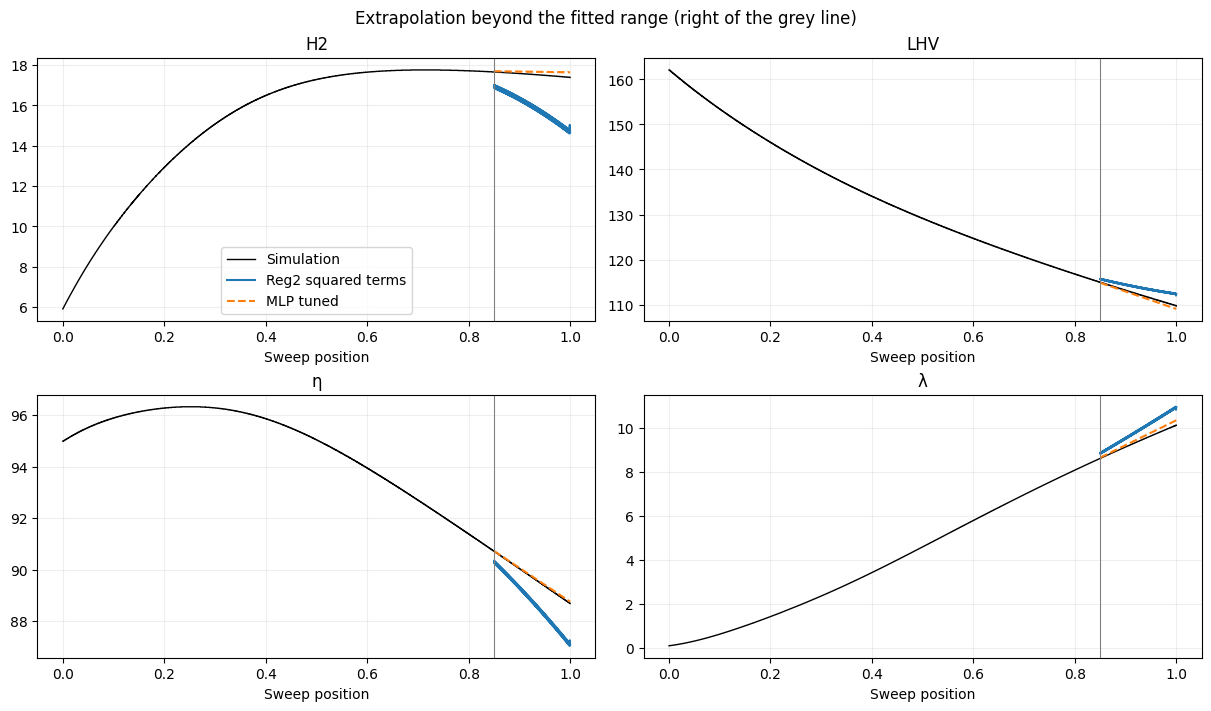

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
order = sweep_position.sort_values().index
outer_order = sweep_position.loc[outer_y.index].sort_values().index
for ax, target in zip(axes.flat, targets):
    ax.plot(sweep_position[order], data_y.loc[order, target], "k-", lw=1, label="Simulation")
    for name, ls in [(best_regression_name, "-"), (best_ann_name, "--")]:
        ax.plot(sweep_position[outer_order],
                extrapolation_predictions[name].loc[outer_order, target],
                lw=1.5, ls=ls, label=name)
    ax.axvline(EXTRAPOLATION_CUTOFF, color="grey", lw=0.8)
    ax.set(title=target, xlabel="Sweep position")
    ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle("Extrapolation beyond the fitted range (right of the grey line)")
fig.savefig("extrapolation_check.png", dpi=160)
plt.show()